# Bluesky Opinions on AI vs SI #
### Report by: Derek Galperin ###

#### I believe that users views in replies to posts about AI vs SI* will be both negative in nature. But through the viewing of other top words in replies, there will be an indication of diffrerent reasons for negative views. ####

##### Using the 'search posts' and 'get post thread' endpoints of the Bluesky API, I plan to find posts that contain the words AI and SI using the search posts endpoint and then using the post thread endpoint I will find information of the top words within replies. I will use the top 300 posts from each and then find the top 50 words. 
 **The executive branch shall use the terms “Super Intelligence” and “SI” in place of “Artificial Intelligence” and “AI” and will not acknowledge the usage of “Artificial Intelligence” and “AI” in any applicable setting (https://www.whitehouse.gov/presidential-actions/2026/09/inaugurating-the-era-of-super-intelligence/).*

My data maybe be unreliable in the sense that the opinions towards SI may be be swayed because of political reasons. I did however account for this in my hypothesis. I think the lack of context about the top words in replies may reduce certaintly in my conclusion. But I think that the data should provide enough information to make a solid assumption on the reasoning behind the users opinions. 

While I am aware that the API may return posts for "SI" that are in a language different than English, I will do my best to restrict it to relevant posts.

### Throughout the code, Claude Sonnet 5.5 was used to assist with syntax. ###

In [3]:
import requests
import pandas as pd
from getpass import getpass

handle = "dgalp.bsky.social"
app_password = getpass("App password: ")

url = "https://bsky.social/xrpc/com.atproto.server.createSession"

payload = {
    "identifier": handle,
    "password": app_password
}
response = requests.post(url, json=payload, timeout=10)

print(response.status_code)

token = response.json()["accessJwt"]
headers = {"Authorization": f"Bearer {token}"}

App password:  ········


200


In [7]:
import os
import time
import requests
import pandas as pd
from getpass import getpass

In [4]:
search_url = "https://bsky.social/xrpc/app.bsky.feed.searchPosts"

def search_posts(term, max_posts=500, **extra):
    posts, cursor = [], None
    while len(posts) < max_posts:
        params = {"q": term, "limit": 100, "sort": "latest", **extra}
        if cursor:
            params["cursor"] = cursor
        r = requests.get(search_url, params=params, headers=headers, timeout=10)
        r.raise_for_status()
        data = r.json()
        posts += data["posts"]
        cursor = data.get("cursor")
        if not cursor:
            break
        time.sleep(0.5)
    return posts

In [8]:
groups = {
    "AI": ["AI", '"artificial intelligence"'],
    "SI": ["SI", '"super intelligence"', "superintelligence"],
}

rows = []
for group, terms in groups.items():
    for term in terms:
        posts = search_posts(
            term,
            max_posts=2000,
            since="2026-09-01T00:00:00Z",
            until="2026-10-22T00:00:00Z",
            lang="en",
        )
        for p in posts:
            rows.append({
                "group": group,
                "term": term,
                "uri": p["uri"],
                "author": p["author"]["handle"],
                "text": p["record"]["text"],
                "created_at": p["record"]["createdAt"],
                "likes": p["likeCount"],
                "replies": p["replyCount"],
            })

df = pd.DataFrame(rows).drop_duplicates(subset=["group", "uri"])
df.to_csv("posts.csv", index=False)

print(df.groupby(["group", "term"]).size())

group  term                     
AI     "artificial intelligence"    2063
       AI                           2069
SI     "super intelligence"         2025
       SI                           2085
       superintelligence            2038
dtype: int64


In [14]:
to_fetch = df[df["replies"] > 0]
print(len(df[df["replies"] > 0]), "posts have replies")

2581 posts have replies


In [15]:
thread_url = "https://bsky.social/xrpc/app.bsky.feed.getPostThread"

def get_replies(node):
    found = []
    for reply in node.get("replies", []):
        if "post" in reply:
            found.append(reply["post"])
            found += get_replies(reply)
    return found

In [16]:
reply_rows = []
failed = 0

try:
    for i, row in enumerate(to_fetch.itertuples(), 1):
        for attempt in range(3):
            r = requests.get(thread_url, params={"uri": row.uri, "depth": 10}, headers=headers, timeout=10)
            if r.status_code == 429:
                time.sleep(30)
                continue
            break

        if r.status_code != 200:
            failed += 1
        else:
            for p in get_replies(r.json()["thread"]):
                reply_rows.append({
                    "group": row.group,
                    "parent_uri": row.uri,
                    "uri": p["uri"],
                    "author": p["author"]["handle"],
                    "text": p["record"]["text"],
                    "created_at": p["record"]["createdAt"],
                })

        if i % 250 == 0:
            print(f"{i}/{len(to_fetch)} done, {len(reply_rows)} replies, {failed} failed")
        time.sleep(0.2)
except KeyboardInterrupt:
    print("Stopped early, keeping what was collected.")

replies_df = pd.DataFrame(reply_rows).drop_duplicates(subset=["group", "uri"])
replies_df.to_csv("replies.csv", index=False)

print(len(replies_df), "replies,", failed, "failed requests")
print(replies_df.groupby("group").size())

250/2581 done, 554 replies, 0 failed
500/2581 done, 1210 replies, 0 failed
750/2581 done, 2103 replies, 1 failed
1000/2581 done, 2896 replies, 1 failed
1250/2581 done, 3725 replies, 1 failed
1500/2581 done, 4693 replies, 1 failed
1750/2581 done, 5580 replies, 1 failed
2000/2581 done, 6424 replies, 1 failed
2250/2581 done, 7335 replies, 1 failed
2500/2581 done, 8462 replies, 1 failed
7971 replies, 1 failed requests
group
AI    2453
SI    5518
dtype: int64


In [18]:
import re
from collections import Counter

stopwords = set("""the and for that this with you are but not have was they from can all what about just
like its your out has had been their there will would who how more when one our get got him her she his
them then than too very also into only some any these those which were why because while over such
dont don't it's i'm i've that's then them yes yeah que les los una por est con las para pero pas des c'est qui """.split())

def top_words(texts, n=50):
    words = []
    for t in texts:
        t = re.sub(r"https?://\S+|@\S+", "", t.lower())
        words += [w for w in re.findall(r"[a-z']+", t) if w not in stopwords and len(w) > 2]
    return Counter(words).most_common(n)

top = {g: top_words(sub["text"]) for g, sub in replies_df.groupby("group")}
pd.DataFrame({g: [f"{w} ({c})" for w, c in words] for g, words in top.items()})

,AI,SI
0,people (185),accounts (372)
1,work (116),shared (372)
2,now (113),intelligence (305)
3,think (110),people (276)
4,make (102),think (220)
5,use (96),trump (206)
6,com (89),super (174)
7,know (88),now (158)
8,could (88),com (156)
9,good (88),even (135)


Due to the complexity of what I was attempting to do, this code was heavily created with Claude as previously cited. I also went through and picked out a few non-english words to add to the list of removed non-impactful words that were excluded from the count.

In [20]:
import re

patterns = {
    "good": r"\bgood\b",
    "positive": r"\bpositive\b",
    "great": r"\bgreat\b",
    "human": r"\bhumans?\b",
    "job": r"\bjobs?\b",
    "bad": r"\bbad\b",
    "negative": r"\bnegative\b",
    "no good": r"\bno good\b",
    "trump": r"\btrump\b",
    "government": r"\bgovernments?\b",
}

print(replies_df["group"].value_counts())

rows = []
for group, sub in replies_df.groupby("group"):
    for label, pat in patterns.items():
        n = sub["text"].str.contains(pat, case=False, regex=True).sum()
        rows.append({"group": group, "word": label, "replies": n, "pct": n / len(sub) * 100})

word_counts = pd.DataFrame(rows)
word_counts.pivot(index="word", columns="group", values="replies").reindex(list(patterns))

group
SI    5518
AI    2453
Name: count, dtype: int64


group,AI,SI
word,,
good,80,104
positive,3,4
great,34,34
human,74,184
job,37,23
bad,46,52
negative,6,5
no good,0,0
trump,34,196


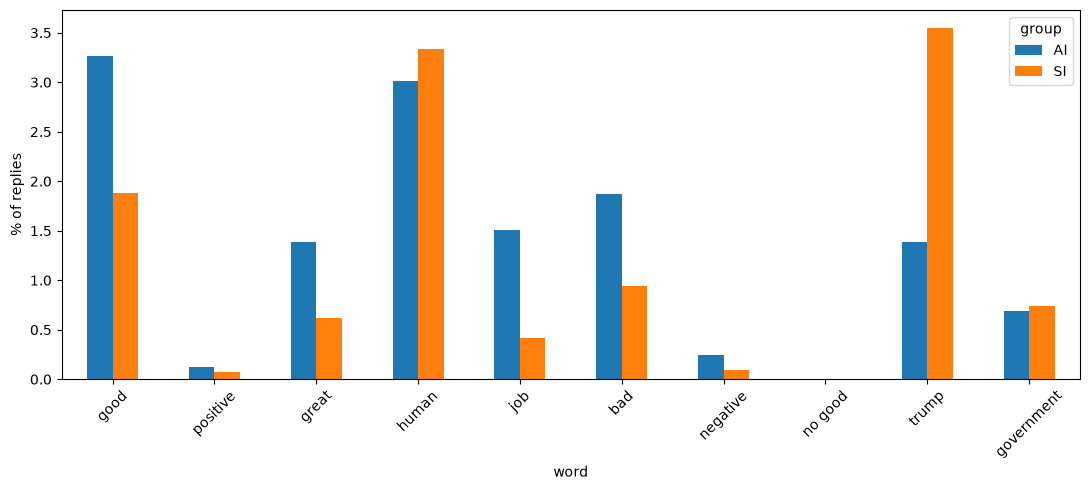

In [21]:
import matplotlib.pyplot as plt

(word_counts.pivot(index="word", columns="group", values="pct")
    .reindex(list(patterns))
    .plot.bar(figsize=(11, 5), ylabel="% of replies"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("word_search.png", dpi=150, bbox_inches="tight")
plt.show()

I felt that the original idea to look at the top words was hard to pull a conclusion out of the data. So I have pivoted to looking at specific keywords that I designated in an effort to have more conclusive data.

In [23]:
buckets = {
    "positive": r"(?<!no )(?<!not )\b(?:good|positive|great)\b",
    "negative": r"\b(?:bad|negative|no good|not good)\b",
}

rows = []
for group, sub in replies_df.groupby("group"):
    pos = sub["text"].str.contains(buckets["positive"], case=False, regex=True)
    neg = sub["text"].str.contains(buckets["negative"], case=False, regex=True)
    rows.append({
        "group": group,
        "total replies": len(sub),
        "positive": pos.sum(),
        "negative": neg.sum(),
        "both": (pos & neg).sum(),
        "positive %": pos.mean() * 100,
        "negative %": neg.mean() * 100,
    })

sentiment = pd.DataFrame(rows).set_index("group")
sentiment

,total replies,positive,negative,both,positive %,negative %
group,,,,,,
AI,2453,113,55,8,4.606604,2.242152
SI,5518,134,59,4,2.428416,1.069228


Claude once again to group the words in relies in specific buckets. 

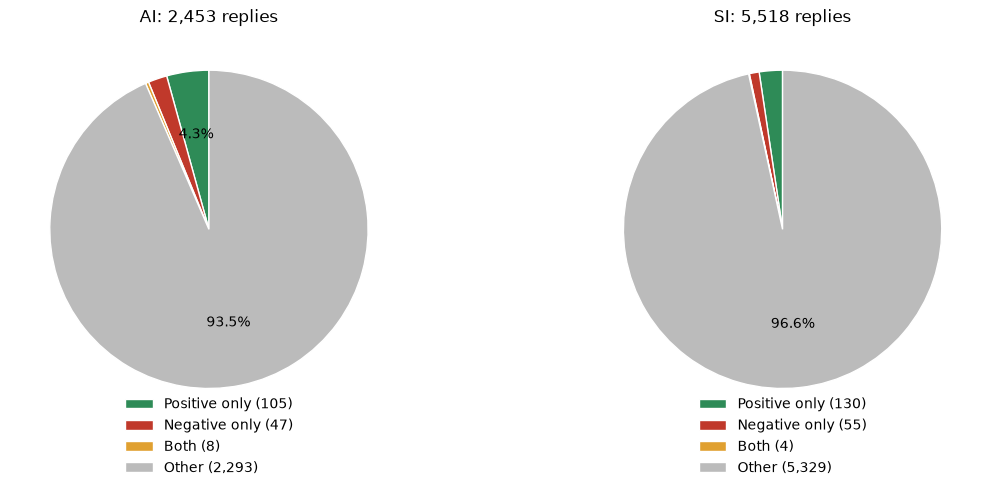

In [24]:
import matplotlib.pyplot as plt

buckets = {
    "positive": r"(?<!no )(?<!not )\b(?:good|positive|great)\b",
    "negative": r"\b(?:bad|negative|no good|not good)\b",
}
colors = {"Positive only": "#2e8b57", "Negative only": "#c0392b", "Both": "#e0a030", "Other": "#bbbbbb"}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (group, sub) in zip(axes, replies_df.groupby("group")):
    pos = sub["text"].str.contains(buckets["positive"], case=False, regex=True)
    neg = sub["text"].str.contains(buckets["negative"], case=False, regex=True)

    counts = {
        "Positive only": (pos & ~neg).sum(),
        "Negative only": (neg & ~pos).sum(),
        "Both": (pos & neg).sum(),
        "Other": (~pos & ~neg).sum(),
    }
    counts = {k: v for k, v in counts.items() if v > 0}   # skip empty slices

    ax.pie(
        counts.values(),
        colors=[colors[k] for k in counts],
        autopct=lambda p: f"{p:.1f}%" if p >= 3 else "",
        startangle=90,
        wedgeprops={"edgecolor": "white"},
    )
    ax.legend(
        [f"{k} ({v:,})" for k, v in counts.items()],
        loc="lower center", bbox_to_anchor=(0.5, -0.15), frameon=False,
    )
    ax.set_title(f"{group}: {len(sub):,} replies")

plt.tight_layout()
plt.savefig("positive_negative_pies.png", dpi=150, bbox_inches="tight")
plt.show()

I believe that there are more responses in the "SI" group due to the word being common in Spanish. However it is interesting to see how similar the numbers are in the positive and negative groups across the board.

## Summary ##

### After shifting my data in an attempt to find more conclusive infomation, there was still little to find. There was little difference in literal numbers between the two categories however due to the number of replies to each, AI takes the edge in the positive category reaching 4.3% of replies falling in that bucket. I would say that the data is largely inconclusive due to the lack of context to the replies and initial posts, but I was not expecting more positive views towards both. I think if this was to be checked again in a month with a new start date after the switch to SI being the prominent media term, than there would be different results to find. I would also be intersted to dive deeper and look at posts from news sources instead of a general search. ###